In [1]:
%%capture
%pip install emoji markdown2
%pip install nltk
%pip install language_tool_python
%pip install transformers[torch,tensorflow]
%pip install language_tool_python
%pip install -U pip setuptools wheel
%pip install -U numpy==1.24.4 spacy==3.7.4 thinc==8.2.3
%pip install https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl
%pip install https://s3-us-west-2.amazonaws.com/ai2-s2-scispacy/releases/v0.5.4/en_core_sci_scibert-0.5.4.tar.gz
%pip install pip install scispacy
%pip install justext
%pip install wordcloud
%pip install nltk
%pip install contractions
%pip install langdetect
%pip install autocorrect
%pip install pyLDAvis
%pip install language-tool-python

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
#import libraries
import markdown2
import os
import re
import argparse
from pathlib import Path
import pandas as pd
import unicodedata
import emoji
import nltk
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from google.colab import drive
from bs4 import BeautifulSoup
import string
import itertools
import contractions
from wordcloud import WordCloud
import nltk
from nltk.probability import FreqDist
import spacy
import en_core_web_sm
nltk.download('words')
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')
nltk.download("punkt_tab")
import justext
import requests

/usr/local/lib/python3.12/dist-packages/spacy/util.py:910: UserWarning: [W095] Model 'en_core_web_sm' (3.8.0) was trained with spaCy v3.8.0 and may not be 100% compatible with the current version (3.7.5). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)
[nltk_data] Downloading package words to /root/nltk_data...
[nltk_data]   Unzipping corpora/words.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [2]:
#switch of deprecation warning
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Data Cleaning Functions

In [3]:
# Define your search terms
keywords = {
    "diagnosis": "glycated haemoglobin|HbA1c|A1C|oral glucose tolerance test|fasting plasma glucose",
    "management": "glycaemic control|blood pressure control|cholesterol control|self-monitoring of blood glucose|continuous glucose monitoring|foot exam|retinopathy screening|psychosocial + diabetes|mental health support + diabetes",
    "medication": (
        "Biguanides|Metformin|Sulfonylureas|Gliclazide|Glipizide|Glibenclamide|Glimepiride|"
        "Dipeptidyl Peptidase-4 Inhibitors|DPP-4 Inhibitors|Sitagliptin|Vildagliptin|Saxagliptin|"
        "Sodium-Glucose Cotransporter-2 Inhibitors|SGL-2 Inhibitors|Dapagliflozin|Empagliflozin|"
        "Glucagon-Like Peptide-1 Agonists|GLP-1 Agonists|Liraglutide|Exenatide|Dulaglutide|"
        "Semaglutide|Lixisenatide|Tirzepatide|Thiazolidinediones|Pioglitazone|Insulin"
    ),
    "diabetes": "diabetes|T1D|T2D|blood sugar|diabetic ketoacidosis|DKA|pancreas|blood glucose|diabetic|hypoglycaemia|hyperglycaemia|prediabetes|gestational diabetes",
}

exclusion_words = "insulinoma|short bowel syndrome|hypopituitarism|insipidus"

# Example usage:
print(keywords["medication"])

Biguanides|Metformin|Sulfonylureas|Gliclazide|Glipizide|Glibenclamide|Glimepiride|Dipeptidyl Peptidase-4 Inhibitors|DPP-4 Inhibitors|Sitagliptin|Vildagliptin|Saxagliptin|Sodium-Glucose Cotransporter-2 Inhibitors|SGL-2 Inhibitors|Dapagliflozin|Empagliflozin|Glucagon-Like Peptide-1 Agonists|GLP-1 Agonists|Liraglutide|Exenatide|Dulaglutide|Semaglutide|Lixisenatide|Tirzepatide|Thiazolidinediones|Pioglitazone|Insulin


In [4]:
#Extract json question answer pairs
nlp = spacy.load("en_core_web_sm")
def read_all_json_files(root_folder):
    """
    Recursively find all Markdown files (.md) under the root_folder,
    including subdirectories, and return their full paths as a list.
    """
    file_paths = []
    for dirpath, _, filenames in os.walk(root_folder):
        for filename in filenames:
            if filename.lower().endswith(".json"):
                filepath = os.path.join(dirpath, filename)
                file_paths.append(filepath)
    return file_paths

/usr/local/lib/python3.12/dist-packages/spacy/util.py:910: UserWarning: [W095] Model 'en_core_web_sm' (3.8.0) was trained with spaCy v3.8.0 and may not be 100% compatible with the current version (3.7.5). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


In [5]:
import language_tool_python
from joblib import Parallel, delayed
#tool = language_tool_python.LanguageTool('en-ZA')
def grammarCorrector(text, n_jobs=-1):
    tool = language_tool_python.LanguageTool('en-ZA')
    corrected_texts =   delayed(tool.correct)(text)
    return corrected_texts

In [6]:
def clean_markdown_content(text, keep_code=False, preserve_case=True):
    """
    Cleans markdown text for RAG ingestion with some improvements.

    Args:
        text (str): The raw markdown text.
        keep_code (bool): If True, keeps code blocks and inline code.
        preserve_case (bool): If True, does not lowercase text.

    Returns:
        str: Cleaned text.
    """

    # 1. Lowercase (unless preserving case)
    if not preserve_case:
        text = text.lower()

    # 2. Remove emojis
    text = emoji.replace_emoji(text, replace="")

    # 3. Remove YAML frontmatter
    text = re.sub(r'^---\s*\n.*?\n---\s*\n', '', text, flags=re.DOTALL)

    # 4 & 5. Remove code blocks and inline code if keep_code is False
    if not keep_code:
        # Remove code blocks (```...```)
        text = re.sub(r'```.*?```', '', text, flags=re.DOTALL)
        # Remove inline code (`...`)
        text = re.sub(r'`[^`]*`', '', text)

    # 6. Remove markdown images ![alt](url)
    text = re.sub(r'!\[.*?\]\(.*?\)', '', text)

    # 7. Remove markdown links [text](url) → keep text
    text = re.sub(r'\[([^\]]+)\]\([^\)]+\)', r'\1', text)

    # 8. Remove email addresses
    text = re.sub(r'\b[\w\.-]+@[\w\.-]+\.\w+\b', '', text)

    # 9. Remove URLs (http/https/www)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # 10. Remove bold and italic markdown
    text = re.sub(r'(\*\*|__)(.*?)\1', r'\2', text)
    text = re.sub(r'(\*|_)(.*?)\1', r'\2', text)

    # 11. Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)

    # 12. Also remove blockquotes, lists, and horizontal rules as before
    text = re.sub(r'^>\s?', '', text, flags=re.MULTILINE)
    text = re.sub(r'^[-*+]\s+', '', text, flags=re.MULTILINE)
    text = re.sub(r'^\d+\.\s+', '', text, flags=re.MULTILINE)
    text = re.sub(r'^-{3,}|^\*{3,}|^_{3,}', '', text, flags=re.MULTILINE)

    # 13. Replace repeated punctuation (e.g., "!!!" → "!")
    text = re.sub(r'([.,!?;:])\1+', r'\1', text)

    # 14. Normalize excessive newlines (more than 2 → 2)
    text = re.sub(r'\n{3,}', '\n\n', text)

    # 15. Strip trailing spaces per line
    text = '\n'.join(line.rstrip() for line in text.splitlines())

    # 16. Unicode normalization (NFKD) - this removes accents, optional, keep or remove as needed
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode('utf-8')

    # 17. Remove '#' from text
    text = re.sub(r'#', '', text)

    # 18. Final trim
    # Remove "Figure <number>[optional letter]"
    text = re.sub(r'\bFigure\s+\d+[a-zA-Z]?\b', '', text)
    text = re.sub(r'\bPage\s+\d+[a-zA-Z]?\b', '', text)
    text = re.sub(r'55393_PT.*?(?:AM|PM)', '', text)

    #19. de-identify
    # Remove email addresses
    text = re.sub(r'\b[\w\.-]+@[\w\.-]+\.\w+\b', '[EMAIL]', text)

    # Remove phone numbers (simple patterns)
    text = re.sub(r'\b(?:\+?\d{1,3})?[-.\s]?(\(?\d{3}\)?)[-.\s]?\d{3}[-.\s]?\d{4}\b', '[PHONE]', text)

    # Remove SSNs (US)
    text = re.sub(r'\b\d{3}-\d{2}-\d{4}\b', '[SSN]', text)

    # Remove IP addresses
    text = re.sub(r'\b(?:\d{1,3}\.){3}\d{1,3}\b', '[IP]', text)

    #From COS802
    # Updated extra longeted text
    text = re.sub(r'(.)\1{3,}', r'\1\1\1', text)

    # Remove special characters (keeps letters, digits, underscore, whitespace)
    #text = re.sub(r"[^\w\s]", ' ', text)

    # Fix contractions
    text = contractions.fix(text)

    # Normalize spaces (instead of removing numbers)
    text = re.sub(r'\s+', ' ', text).strip()

    # Add a space after any punctuation if it’s not followed by a space
    text = re.sub(r'([.,!?;:])(?=\S)', r'\1 ', text)

    # Remove space before punctuation
    text = re.sub(r'\s+([.,!?;:])', r'\1', text)

    # using spacy to remove persons name
    doc = nlp(text)
    redacted = text
    #for ent in reversed(doc.ents):  # reverse so indices stay valid when replacing
        #if ent.label_ in ("PERSON"):
            #redacted = redacted[:ent.start_char] + f"[{ent.label_}]" + redacted[ent.end_char:]
    return redacted.strip()


In [7]:
def extract_dataframes(markdown_paths):
  # Create an empty list to store individual DataFrames
  all_dataframes = []
  # Iterate through the list of file paths
  for file_path in markdown_paths:
      try:
          # Read each JSON file into a DataFrame
          df = pd.read_json(file_path)
          module = file_path.split('/')[-1].split('.')[0]
          if "module" not in df.columns:
            df["module"] = module
          # Append the DataFrame to the list
          all_dataframes.append(df)
      except Exception as e:
          print(f"Error reading file {file_path}: {e}")
  # Concatenate all DataFrames into a single DataFrame
  df = pd.concat(all_dataframes, ignore_index=True)
  return df

In [8]:
#keywords search
def keywords_search(df, keywords):
  used_indices = set()
  filtered_dfs = []
  for keyword_key in keywords.keys():
    for col in df.columns:
      mask = (
          (df[col].astype(str).str.lower()).str.contains(keywords[keyword_key], na=False)|
          (df[col].astype(str)).str.contains(keywords[keyword_key], na=False)
      )
      # Exclude rows already used
      available_mask = mask & ~ df.index.isin(used_indices)

      df_filtered = df[available_mask].copy()
      df_filtered['subtopic_name'] = keyword_key

      # Update used indices
      used_indices.update(df_filtered.index)
      filtered_dfs.append(df_filtered)
  return pd.concat(filtered_dfs, ignore_index=True)

In [9]:
import unicodedata
import re

def clean_text(text, keep_punct=True):
    # Normalize first (fix widths, compatibility forms)
    text = unicodedata.normalize("NFKC", text)

    # Allow letters, numbers, and spaces. Optionally keep common punctuation.
    # Using character classes instead of Unicode properties for broader compatibility
    allowed = r"a-zA-Z0-9\s"
    punct = r"\.,;:!\?\'\"()\-\[\]/#@&%€$"  # adjust to your needs
    pattern = fr"[^{allowed}{punct}]" if keep_punct else fr"[^{allowed}]"

    text = re.sub(pattern, " ", text)
    text = text.lower()
    text = re.sub(r"[^\w\s]", " ", text)

    # collapse whitespace
    return re.sub(r"\s+", " ", text).strip()

In [10]:
import nltk
from nltk.corpus import stopwords
import re

# First time only:
stop_words = set(stopwords.words("english"))

def remove_stopwords(text):
    # Tokenize by words
    text = clean_text(text)
    words = nltk.word_tokenize(text)
    # Filter out stopwords
    filtered = [w for w in words if w.lower() not in stop_words]
    return " ".join(filtered)

# Benchmark

In [11]:
#QA pairs
markdown_paths_bn = [ '/content/drive/MyDrive/MIT807/data/raw/benchmark/squad_test.json',
 '/content/drive/MyDrive/MIT807/data/raw/benchmark/squad_train.json']
benchmark_df = extract_dataframes(markdown_paths=markdown_paths_bn).drop(columns=['id', 'title', 'is_impossible'])
benchmark_df['answers'] = benchmark_df['answers'].astype(str).str.replace(r'\[\]', 'nan', regex=True)
benchmark_df['answers'] = benchmark_df['answers'].replace('nan', np.nan)
benchmark_df['answers'] = benchmark_df['answers'].apply(lambda x: (x.split()[1]).replace("'",'').replace(',','') if pd.notna(x) else np.nan)
benchmark_df['plausible_answers'] = benchmark_df['plausible_answers'].apply(lambda x: x[0].get('text') if pd.notna(x) else np.nan)
benchmark_df['answer'] = benchmark_df['answers']\
                          .fillna(benchmark_df['plausible_answers'])\
                          .fillna(benchmark_df['plausible_answers'])
benchmark_df['kind'] = benchmark_df['module'].str.split("_").str[1]
benchmark_df['module'] = benchmark_df['module'].str.split("_").str[0]
benchmark_df.drop(columns=['answers','plausible_answers'], inplace=True)
benchmark_df = benchmark_df.drop_duplicates(subset=['question', 'answer'])
benchmark_df.info()
benchmark_df.head(2)

<class 'pandas.core.frame.DataFrame'>
Index: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   question       20 non-null     object
 1   subtopic_name  20 non-null     object
 2   module         20 non-null     object
 3   answer         20 non-null     object
 4   kind           20 non-null     object
dtypes: object(5)
memory usage: 960.0+ bytes


,question,subtopic_name,module,answer,kind
0,Which Iranian scientist discovered HbA1c to fu...,diagnosis,squad,Samuel,test
1,Insulin resistance has been strongly linked to...,medication,squad,obesity,test


In [12]:
#MCQ
root_directory  = "/content/drive/MyDrive/MIT807/data/raw/benchmark/"
markdown_paths = list(set(read_all_json_files(root_directory)) - set(markdown_paths_bn))
benchmark_mcq_df = extract_dataframes(markdown_paths=markdown_paths)
benchmark_mcq_df = benchmark_mcq_df[['question', 'answer', 'options', 'meta_info', 'long_answer', 'context', 'module']]
benchmark_mcq_df = benchmark_mcq_df.sort_values(by = ['question', 'answer', 'long_answer',], ascending=False)
benchmark_mcq_df = benchmark_mcq_df.drop_duplicates(subset=['question', 'answer'])
benchmark_mcq_df['kind'] = benchmark_mcq_df['module'].str.split("_").str[1]
benchmark_mcq_df['module'] = benchmark_mcq_df['module'].str.split("_").str[0]
benchmark_mcq_df.dropna(subset= 'answer',inplace=True)
benchmark_mcq_df.info()
benchmark_mcq_df.head(2)

<class 'pandas.core.frame.DataFrame'>
Index: 17708 entries, 9668 to 2158
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   question     17708 non-null  object
 1   answer       17708 non-null  object
 2   options      17708 non-null  object
 3   meta_info    8350 non-null   object
 4   long_answer  15606 non-null  object
 5   context      9358 non-null   object
 6   module       17708 non-null  object
 7   kind         8350 non-null   object
dtypes: object(8)
memory usage: 1.2+ MB


,question,answer,options,meta_info,long_answer,context,module,kind
9668,“Flipping effect” is ?,LDH 1> LDH 2,"{'A': 'LDH 1> LDH 2', 'B': 'LDH2>LDH1', 'C': '...","{'subject_name': 'Unknown', 'topic_name': None...",Ref. API Textbook of Medicine. Pg. 798\n \nLac...,NaN,mcqa,train
3302,А 55-уеаr-old mаn рrеѕеntѕ to hіѕ рrіmаrу саrе...,Failure of adequate erythropoietin production,"{'A': 'Progressive metabolic acidosis', 'B': '...","{'process_step': 'step1', 'subtopic_name': 'di...",NaN,NaN,medqa,train


In [13]:
# Store filtered DataFrames in a list
final_benchmark_df = pd.concat([benchmark_df, benchmark_mcq_df])
used_indices = set()
filtered_dfs = []

for keyword_key in keywords.keys():
    # Ensure 'context' column is string type before applying .str
    final_benchmark_df['context'] = final_benchmark_df['context'].astype(str)
    mask = (
        (final_benchmark_df['question'].str.lower()).str.contains(keywords[keyword_key].lower(), na=False) |
        (final_benchmark_df['answer'].str.lower()).str.contains(keywords[keyword_key].lower(), na=False) |
        (final_benchmark_df['context'].str.lower()).str.contains(keywords[keyword_key].lower(), na=False)
    )

    # Exclude rows already used
    available_mask = mask & ~ final_benchmark_df.index.isin(used_indices)

    df_filtered = final_benchmark_df[available_mask].copy()
    df_filtered['category'] = keyword_key

    # Update used indices
    used_indices.update(df_filtered.index)
    filtered_dfs.append(df_filtered)

# Combine all into one DataFrame
final_benchmark_df = pd.concat(filtered_dfs, ignore_index=True)
final_benchmark_df = final_benchmark_df.drop_duplicates(subset=['question', 'answer'])
final_benchmark_df  = final_benchmark_df.drop_duplicates(subset=['question'])
final_benchmark_df.info()
final_benchmark_df.head(2)

<class 'pandas.core.frame.DataFrame'>
Index: 13681 entries, 0 to 13681
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   question       13681 non-null  object
 1   subtopic_name  12 non-null     object
 2   module         13681 non-null  object
 3   answer         13681 non-null  object
 4   kind           4547 non-null   object
 5   options        13669 non-null  object
 6   meta_info      4535 non-null   object
 7   long_answer    11601 non-null  object
 8   context        13681 non-null  object
 9   category       13681 non-null  object
dtypes: object(10)
memory usage: 1.1+ MB


,question,subtopic_name,module,answer,kind,options,meta_info,long_answer,context,category
0,Which Iranian scientist discovered HbA1c to fu...,diagnosis,squad,Samuel,test,NaN,NaN,NaN,nan,diagnosis
1,А 43-уеаr-old mаn рrеѕеntѕ wіth tіnglіng аnd n...,NaN,medqa,Strict blood glucose control,test,"{'A': 'Use of atorvastatin', 'B': 'Femoro-Ilea...","{'process_step': 'step1', 'subtopic_name': 'di...",NaN,nan,diagnosis


In [14]:
final_benchmark_df['module'].value_counts()


,count
module,
pubmedpqaa,9134
mcqa,2674
medqa,1393
mmlu,468
squad,12


# Huggingface

In [15]:
markdown_paths = ['/content/drive/MyDrive/MIT807/data/raw/supplementary_data/healthcare_facts.json']
hf_qa_df = extract_dataframes(markdown_paths).drop(columns='text')
hf_qa_df = hf_qa_df.drop_duplicates(subset=['input', 'output'])
hf_qa_df = hf_qa_df.drop_duplicates(subset=['output'])
hf_qa_df = hf_qa_df.drop_duplicates(subset=['input'])
afrimed_df = pd.read_json( '/content/drive/MyDrive/MIT807/data/raw/supplementary_data/afrimed.json')
afrimed_df = afrimed_df[afrimed_df['question_type'] != 'mcq'][['prompt', 'question', 'answer_rationale','subtopic_name']]
afrimed_df['module'] = 'AfriMed'
afrimed_df.columns = ['instruction', 'input', 'output', 'subtopic_name', 'module']
afrimed_df = afrimed_df.drop_duplicates(subset=['input', 'output'])
#databricks
databricks_df = pd.read_json("/content/drive/MyDrive/MIT807/data/raw/supplementary_data/databricks.json").drop(columns='category')
databricks_df.columns = ['input', 'context', 'output', 'subtopic_name']
hf_qa_df = pd.concat([hf_qa_df, afrimed_df, databricks_df]).drop_duplicates()
hf_qa_df = hf_qa_df.sort_values(by=['input','instruction','context'],ascending=False)
hf_qa_df = hf_qa_df.drop_duplicates(subset=['input', 'output'])
hf_qa_df = hf_qa_df.drop_duplicates(subset=['output'])
hf_qa_df = hf_qa_df.drop_duplicates(subset=['input'])
hf_qa_df.columns = ['instruction', 'question', 'answer', 'subtopic_name', 'module', 'context']
hf_qa_df.info()
hf_qa_df.head(2)

<class 'pandas.core.frame.DataFrame'>
Index: 1456 entries, 78 to 598
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   instruction    1456 non-null   object
 1   question       1456 non-null   object
 2   answer         1455 non-null   object
 3   subtopic_name  1390 non-null   object
 4   module         1416 non-null   object
 5   context        40 non-null     object
dtypes: object(6)
memory usage: 79.6+ KB


,instruction,question,answer,subtopic_name,module,context
78,diabetes,will it have any effect on my job?,None,Your female coworker complains of excessive th...,AfriMed,NaN
16,diabetes,is keto diet healthy?,The keto diet is originally designed in clinic...,NaN,NaN,


In [16]:
o1_df = pd.read_json("/content/drive/My Drive/MIT807/data/raw/supplementary_data/o1_df.json")
o1_df['module'] = "medical-o1-reasoning-SFT"
o1_df.columns = o1_df.columns.str.lower()
o1_df.rename(columns={'response':'answer'}, inplace=True)
hf_qa_df = pd.concat([hf_qa_df, o1_df])
# hf_qa_df['question'] = hf_qa_df['question'].apply(clean_markdown_content)
# hf_qa_df['answer'] = hf_qa_df['answer'].astype(str).apply(clean_markdown_content)
hf_qa_df = hf_qa_df.sort_values(by=['complex_cot', 'context','instruction'],ascending=False)
hf_qa_df = hf_qa_df.drop_duplicates(subset=['question', 'answer'])
hf_qa_df = hf_qa_df.drop_duplicates(subset=['question'])
hf_qa_df.info()
hf_qa_df.head(2)

<class 'pandas.core.frame.DataFrame'>
Index: 2906 entries, 392 to 598
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   instruction    1456 non-null   object
 1   question       2906 non-null   object
 2   answer         2905 non-null   object
 3   subtopic_name  2840 non-null   object
 4   module         2866 non-null   object
 5   context        40 non-null     object
 6   complex_cot    1450 non-null   object
dtypes: object(7)
memory usage: 181.6+ KB


,instruction,question,answer,subtopic_name,module,context,complex_cot
392,NaN,"Following a Billroth-II gastrectomy, a 40-year...",The most probable reason for the patient's col...,diabetes,medical-o1-reasoning-SFT,NaN,"Wow, this is concerning! A patient just collap..."
41,NaN,A 60-year-old man is admitted to the ER with s...,Considering the symptoms and clinical presenta...,diagnosis,medical-o1-reasoning-SFT,NaN,"Wow, this guy is really having a rough time. S..."


In [17]:
# Store filtered DataFrames in a list
used_indices = set()
filtered_dfs = []

for keyword_key in keywords.keys():
    mask = (
        (hf_qa_df['question'].str.lower()).str.contains(keywords[keyword_key].lower()) |
        (hf_qa_df['answer'].str.lower()).str.contains(keywords[keyword_key].lower()) |
        (hf_qa_df['complex_cot'].str.lower()).str.contains(keywords[keyword_key].lower()) |
        (hf_qa_df['context'].str.lower()).str.contains(keywords[keyword_key].lower())
    )

    # Exclude rows already used
    available_mask = mask & ~ hf_qa_df.index.isin(used_indices)

    df_filtered = hf_qa_df[available_mask].copy()
    df_filtered['category'] = keyword_key

    # Update used indices
    used_indices.update(df_filtered.index)
    filtered_dfs.append(df_filtered)

# Combine all into one DataFrame
final_hf_qa_df = pd.concat(filtered_dfs, ignore_index=True)
final_hf_qa_df = final_hf_qa_df.sort_values(by=['complex_cot', 'context', 'instruction'],ascending=False)
final_hf_qa_df['token_question'] = final_hf_qa_df['question'].apply(clean_text)
final_hf_qa_df['token_answer'] = final_hf_qa_df['answer'].apply(clean_text)
final_hf_qa_df = final_hf_qa_df.drop_duplicates(subset=['question', "answer"])
final_hf_qa_df = final_hf_qa_df.drop_duplicates(subset=['token_question', "token_answer"])
# final_hf_qa_df = final_hf_qa_df.drop_duplicates(subset=['question'])
# final_hf_qa_df = final_hf_qa_df.drop_duplicates(subset=['answer'])

final_hf_qa_df.info()
final_hf_qa_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 2463 entries, 777 to 2462
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   instruction     1163 non-null   object
 1   question        2463 non-null   object
 2   answer          2463 non-null   object
 3   subtopic_name   2454 non-null   object
 4   module          2463 non-null   object
 5   context         0 non-null      object
 6   complex_cot     1300 non-null   object
 7   category        2463 non-null   object
 8   token_question  2463 non-null   object
 9   token_answer    2463 non-null   object
dtypes: object(10)
memory usage: 211.7+ KB


,instruction,question,answer,subtopic_name,module,context,complex_cot,category,token_question,token_answer
777,NaN,"Following a Billroth-II gastrectomy, a 40-year...",The most probable reason for the patient's col...,diabetes,medical-o1-reasoning-SFT,NaN,"Wow, this is concerning! A patient just collap...",diabetes,following a billroth ii gastrectomy a 40 year ...,the most probable reason for the patient s col...
0,NaN,A 60-year-old man is admitted to the ER with s...,Considering the symptoms and clinical presenta...,diagnosis,medical-o1-reasoning-SFT,NaN,"Wow, this guy is really having a rough time. S...",diagnosis,a 60 year old man is admitted to the er with s...,considering the symptoms and clinical presenta...
778,NaN,A 57-year-old man with a history of diabetes a...,Given the patient's presentation and the initi...,diabetes,medical-o1-reasoning-SFT,NaN,"Whoa, this guy is showing some serious symptom...",diabetes,a 57 year old man with a history of diabetes a...,given the patient s presentation and the initi...
779,NaN,When considering the use of pseudoephedrine as...,Osteoarthritis does not require cautious use o...,diabetes,medical-o1-reasoning-SFT,NaN,"When I'm thinking about pseudoephedrine, I kno...",diabetes,when considering the use of pseudoephedrine as...,osteoarthritis does not require cautious use o...
167,NaN,Which medication can cause metabolic acidosis ...,Metabolic acidosis in adolescents can indeed b...,medication,medical-o1-reasoning-SFT,NaN,When I think about metabolic acidosis in adole...,medication,which medication can cause metabolic acidosis ...,metabolic acidosis in adolescents can indeed b...


In [18]:
hf_qa_duplicates = final_hf_qa_df[final_hf_qa_df['token_question'].duplicated(keep=False)].sort_values(by='token_question')

# Display them
final_hf_qa_df = final_hf_qa_df[~(final_hf_qa_df['question'].isin(hf_qa_duplicates['question']))]
final_hf_qa_df['module'].value_counts()

,count
module,
medical-o1-reasoning-SFT,1300
healthcare_facts,1150
AfriMed,9


# Custom Data

In [19]:
import re

def split_by_first_number(text):
    match = re.search(r'\d', text)
    if not match:
        return text
    index = match.start()
    return text[:index].strip()


In [20]:
%pip -q install fuzzywuzzy python-Levenshtein
from fuzzywuzzy import process
# Function to find best fuzzy match
def fuzzy_merge(df1, df2, key1, key2, threshold=80):
    matches = []
    # Ensure the column to be searched in df2 is a list of strings
    choices = df2[key2].astype(str).tolist()
    for value in df1[key1]:
        # Ensure the value from df1 is a string
        query = str(value)
        match, score = process.extractOne(query, choices)
        if score >= threshold:
            matches.append(match)
        else:
            matches.append(None)
    df1['best_match'] = matches
    return df1

In [21]:
import json
from itertools import chain
def flatten_data(data):
    flat_list = []

    if isinstance(data, list):
        for item in data:
            flat_list.extend(flatten_data(item))
    elif isinstance(data, dict):
        if 'doc_id' in data and 'qa_json_array' in data:
            doc_id = data['doc_id']
            for qa in data['qa_json_array']:
                flat_list.append({'doc_id': doc_id, **qa})
        else:
            # Regular dict without 'qa_json_array'
            flat_list.append(data)
    else:
        # primitive value
        flat_list.append(data)

    return flat_list

In [22]:
markdown_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/pi_qa.json'
pi_df = pd.read_json(markdown_path)
pi_df["source"] = "professional information"
pi_df['type'] = "QA"
pi_df.drop(columns=[ 'instruction'], inplace=True)
# pi_df.dropna(inplace=True)
pi_df.info()
pi_df.head(1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   drug      217 non-null    object
 1   question  217 non-null    object
 2   answer    217 non-null    object
 3   context   217 non-null    object
 4   source    217 non-null    object
 5   type      217 non-null    object
dtypes: object(6)
memory usage: 10.3+ KB


,drug,question,answer,context,source,type
0,DUFORZIG,What are the therapeutic indications of DUFORZ...,DUFORZIG is indicated in adults aged 18 years ...,A clinician is reviewing DUFORZIG indications ...,professional information,QA


In [23]:
# Load the JSON data from the file
markdown_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/pil_qa.json'
pil_df = pd.read_json(markdown_path)
pil_df["source"] = "patient information leaflet"
pil_df['type'] = "QA"
# pil_df = (pil_df.dropna()).drop(columns=['instruction'])
pil_df.info()
pil_df.head(1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   drug         418 non-null    object
 1   instruction  418 non-null    object
 2   question     418 non-null    object
 3   answer       418 non-null    object
 4   context      418 non-null    object
 5   source       418 non-null    object
 6   type         418 non-null    object
dtypes: object(7)
memory usage: 23.0+ KB


,drug,instruction,question,answer,context,source,type
0,DAPAGLIFLOZIN GLENMARK,Paraphrased from the medication’s indications ...,What is DAPAGLIFLOZIN GLENMARK used for?,It’s an oral medicine for adults with type 2 d...,A patient with type 2 diabetes discusses addin...,patient information leaflet,QA


In [24]:
markdown_path = '/content/drive/MyDrive/MIT807/data/raw/Database-Of-Medicine-Prices_01-September-2025.xlsx'
drugs = pd.read_excel(markdown_path, header=1)
drugs = drugs[['Medicine Proprietary Name', 'Active Ingredients', 'Status', "Effective Date"]]
used_indices = set()
filtered_dfs = []

for keyword_key in keywords.keys():
    mask = (
        (drugs['Medicine Proprietary Name'].str.lower()).str.contains(keywords[keyword_key].lower()) |
        (drugs['Active Ingredients'].str.lower()).str.contains(keywords[keyword_key].lower())
    )

    # Exclude rows already used
    available_mask = mask & ~ drugs.index.isin(used_indices)

    df_filtered = drugs[available_mask].copy()
    df_filtered['category'] = keyword_key

    # Update used indices
    used_indices.update(df_filtered.index)
    filtered_dfs.append(df_filtered)

# Combine all into one DataFrame
final_drugs = pd.concat(filtered_dfs, ignore_index=True)
final_drugs.drop_duplicates(inplace=True)
final_drugs.dropna(inplace=True)
final_drugs['Name'] = final_drugs['Medicine Proprietary Name'].apply(split_by_first_number).str.lower()
final_drugs.info()
final_drugs.head(1)

<class 'pandas.core.frame.DataFrame'>
Index: 20 entries, 169 to 321
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Medicine Proprietary Name  20 non-null     object
 1   Active Ingredients         20 non-null     object
 2   Status                     20 non-null     object
 3   Effective Date             20 non-null     object
 4   category                   20 non-null     object
 5   Name                       20 non-null     object
dtypes: object(6)
memory usage: 1.1+ KB


,Medicine Proprietary Name,Active Ingredients,Status,Effective Date,category,Name
169,Glucovance 250Mg/1.25Mg,Glibenclamide,Discontinued,2019-05-17 00:00:00,medication,glucovance


In [25]:
markdown_path = '/content/drive/MyDrive/MIT807/data/Drugs/json/drug_labels.json'
drugs = pd.read_json(markdown_path)
drugs['Name'] = drugs['Product Name'].apply(split_by_first_number).str.lower()
drugs.head(1)

,API(s),Product Name,HCR,Dosage Form(s),Strength(s),PI,PIL,Approval Date,Name
0,Sitagliptin phosphate monohydrate & metformin ...,METJENTA 50/850 and 50/1 000,Elttab Pharmaceuticals CC,Film-coated tablets.,"50/850 mg, 50/1 000 mg",https://pi-pil-repository.sahpra.org.za/wp-con...,https://pi-pil-repository.sahpra.org.za/wp-con...,10/06/2025,metjenta


In [26]:
pi_pil_df = pd.concat([pi_df,pil_df])
print(pi_pil_df.shape)
pi_pil_df['Name'] = pi_pil_df['drug'].str.split('(', expand=True)[0].str.lower()
pi_pil_df = fuzzy_merge(pi_pil_df, drugs[['API(s)','Name', 'Product Name']].drop_duplicates(), 'Name', 'Name')\
                    .drop(columns='Name')\
                    .rename(columns={'best_match':'Name'})
pi_pil_df = pi_pil_df.merge(drugs[['API(s)','Name', 'Product Name']].drop_duplicates(), on='Name')
pi_pil_df = pi_pil_df.merge(final_drugs[['Name','Status']].drop_duplicates(), on='Name', how='left')
pi_pil_df['drug'] = pi_pil_df['drug'].str.split('(', expand=True)[0] + " (" + pi_pil_df['API(s)'] + ")"
pi_pil_df['answer'] = pi_pil_df.apply(
    lambda x: (
        x['answer'] + f" Note: This product has been {x['Status']}, consult doctor for alternatives"
        if pd.notnull(x['Status'])
        else x['answer']
    ),
    axis=1
)
pi_pil_df = pi_pil_df.drop_duplicates(subset=['question', 'answer'])
pi_pil_df = pi_pil_df.drop(columns=['instruction','API(s)', 'Name'])
pi_pil_df.info()
pi_pil_df.head()

(635, 7)
<class 'pandas.core.frame.DataFrame'>
Index: 635 entries, 0 to 753
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   drug          635 non-null    object
 1   question      635 non-null    object
 2   answer        635 non-null    object
 3   context       635 non-null    object
 4   source        635 non-null    object
 5   type          635 non-null    object
 6   Product Name  635 non-null    object
 7   Status        20 non-null     object
dtypes: object(8)
memory usage: 44.6+ KB


,drug,question,answer,context,source,type,Product Name,Status
0,DUFORZIG (Dapagliflozin propanediol),What are the therapeutic indications of DUFORZ...,DUFORZIG is indicated in adults aged 18 years ...,A clinician is reviewing DUFORZIG indications ...,professional information,QA,DUFORZIG 5/10,NaN
1,DUFORZIG (Dapagliflozin propanediol),What is the recommended starting and maintenan...,The recommended dose is 10 mg DUFORZIG once da...,A patient with newly diagnosed type 2 diabetes...,professional information,QA,DUFORZIG 5/10,NaN
2,DUFORZIG (Dapagliflozin propanediol),Which patients should not use DUFORZIG?,DUFORZIG is contraindicated in hypersensitivit...,A clinician evaluates whether a patient who is...,professional information,QA,DUFORZIG 5/10,NaN
3,DUFORZIG (Dapagliflozin propanediol),What warning should be considered regarding ke...,"There have been reports of ketoacidosis, inclu...",A patient on DUFORZIG presents with nausea and...,professional information,QA,DUFORZIG 5/10,NaN
4,DUFORZIG (Dapagliflozin propanediol),How should DUFORZIG therapy be managed in pati...,No dosage adjustment is required based on rena...,An experienced clinician reviews DUFORZIG use ...,professional information,QA,DUFORZIG 5/10,NaN


In [27]:
markdown_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/medication_guidelines_qa.json'
medication_guidelines_df = pd.read_json(markdown_path)#.drop(columns=['instruction'])
medication_guidelines_df["source"] = "SAHPRA guidelines"
medication_guidelines_df['type'] = "QA"
#medication_guidelines_df.dropna(inplace=True)
medication_guidelines_df.info()
medication_guidelines_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   instruction  29 non-null     object
 1   question     29 non-null     object
 2   answer       29 non-null     object
 3   context      29 non-null     object
 4   extract      29 non-null     object
 5   source       29 non-null     object
 6   type         29 non-null     object
dtypes: object(7)
memory usage: 1.7+ KB


,instruction,question,answer,context,extract,source,type
0,Derived from SAHPRA safety alerts concerning m...,SAHPRA is investigating possible contamination...,N-Nitrosodimethylamine (NDMA).,NDMA is considered a probable human carcinogen...,Metformin – Under Investigation regarding the ...,SAHPRA guidelines,QA
1,Derived from SAHPRA guidance on continuing met...,SAHPRA recommends that metformin should be con...,healthcare professional.,Maintain diabetes control while investigations...,Metformin – Under Investigation regarding the ...,SAHPRA guidelines,QA
2,Derived from ADR reporting pathways outlined b...,"If a side-effect is suspected with metformin, ...",Report to the SAHPRA Vigilance Unit by telepho...,Adverse drug reaction reporting channels inclu...,Metformin – Under Investigation regarding the ...,SAHPRA guidelines,QA
3,Derived from SAHPRA statements about Ozempic a...,Ozempic (semaglutide) is a Schedule 4 prescrip...,weight loss.,Semaglutide is a GLP-1 receptor agonist; regul...,Public urged to use registered Ozempic products,SAHPRA guidelines,QA
4,Derived from SAHPRA’s Ozempic registration det...,There are two registered Ozempic pen presentat...,1,"Registered presentations include 0.25 mg, 0.5 ...",Public urged to use registered Ozempic products,SAHPRA guidelines,QA


In [28]:
markdown_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/qna_qa_old.json'
qna_json= pd.read_json(markdown_path)
qna_json.rename(columns={'category':'source'}, inplace=True)
qna_json.dropna(subset=['answer'], inplace=True)
qna_pairs_df = pd.concat([ qna_json])
qna_pairs_df['source'] = "FAQ and Other QAs"
qna_pairs_df['options'] = qna_pairs_df['options'].replace('{}', np.nan)
qna_pairs_df['type'] = qna_pairs_df['options'].apply(lambda x: "QA" if pd.isna(x) else "MCQ")
qna_pairs_df.info()
qna_pairs_df.head(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124 entries, 0 to 123
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   question  124 non-null    object
 1   options   60 non-null     object
 2   answer    124 non-null    object
 3   source    124 non-null    object
 4   type      124 non-null    object
dtypes: object(5)
memory usage: 5.0+ KB


,question,options,answer,source,type
0,12.1 Which treatment option is preferred for t...,"{'A': 'Metformin monotherapy', 'B': 'Metformin...",B,FAQ and Other QAs,MCQ
1,12.2 Which of the following is considered not ...,"{'A': 'Diarrhea', 'B': 'Nausea, vomiting, Flat...",C,FAQ and Other QAs,MCQ


In [29]:
def read_json_files(files):
  data_list = [] # Initialize data_list here
  for file_path in files: # Iterate directly through the provided file paths
      with open(file_path, "r") as f:
          try:
              data = json.load(f)
              data_list.append(data)
          except Exception as e:
              print(f"Error reading {file_path}: {e}")
  return data_list

In [30]:
guidelines_path = ['/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/guidelines_qa.json',
 '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/guidelines_fill_blanks.json']
guidelines_df = pd.concat([pd.read_json(guidelines_path[0]), pd.read_json(guidelines_path[1])])
guidelines_df['type'] = guidelines_df['instruction'].apply(lambda x: "Fill-in-blanks" if pd.isna(x) else "QA")
guidelines_df['source'] = "guidelines"
guidelines_df.drop(columns=['instruction'], inplace=True)
guidelines_df.info()
guidelines_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 399 entries, 0 to 197
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   question  399 non-null    object
 1   answer    399 non-null    object
 2   context   399 non-null    object
 3   extract   399 non-null    object
 4   type      399 non-null    object
 5   source    399 non-null    object
dtypes: object(6)
memory usage: 21.8+ KB


,question,answer,context,extract,type,source
0,The three main modalities in the stepwise mana...,insulin,Insulin is a hormone produced by the pancreas ...,The three main modalities in the stepwise mana...,QA,guidelines
1,A PMB-funded plan for Type 2 diabetes includes...,pathology/blood tests at 3-6 monthly intervals,Pathology tests are blood tests used to monito...,The items that the scheme should fund include ...,QA,guidelines
2,"When diabetes presents without symptoms, the d...",test(s),Diagnosis may require repeating glucose tests ...,When someone does not have symptoms of diabete...,QA,guidelines
3,The two-hour post-load glucose test is also kn...,oral glucose tolerance,The oral glucose tolerance test (OGTT) measure...,2 Hour post-load glucose test or oral glucose ...,QA,guidelines
4,Preventive guidance recommends exercising for ...,five,A common target is 150 minutes of moderate act...,Preventive care: reducing risk by losing weigh...,QA,guidelines


In [31]:
facts_path = ['/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/factsheets_qa.json',
 '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/factsheets_fill_blanks.json']
facts_df = pd.concat([pd.read_json(facts_path[0]), pd.read_json(facts_path[1])])
facts_df['type'] = facts_df['instruction'].apply(lambda x: "Fill-in-blanks" if pd.isna(x) else "QA")
facts_df['source'] = "facts"
facts_df.drop(columns=['instruction'], inplace=True)
facts_df.info()
facts_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 40 entries, 0 to 19
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   question  40 non-null     object
 1   answer    40 non-null     object
 2   context   40 non-null     object
 3   extract   40 non-null     object
 4   type      40 non-null     object
 5   source    40 non-null     object
dtypes: object(6)
memory usage: 2.2+ KB


,question,answer,context,extract,type,source
0,"In 2024, about _____ million adults aged 20–79...",589 million,Global prevalence figure for adults 20–79 years.,,QA,facts
1,"In the IDF Africa Region in 2024, the proporti...",72.6%,Undiagnosed diabetes proportion highlights tes...,,QA,facts
2,"For type 2 diabetes, the first-line oral medic...",metformin,Metformin is the standard initial pharmacologi...,,QA,facts
3,A fasting plasma glucose threshold for diagnos...,126 mg/dL (7.0 mmol/L),Fasting glucose thresholds used in diagnosing ...,,QA,facts
4,Hyperglycaemia in pregnancy affects approximat...,five,HIP prevalence reflects gestational diabetes a...,,QA,facts


In [32]:
literature_path = ['/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/literature_qa.json',
 '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/literature_fill_blanks.json']
literature_df = pd.concat([pd.read_json(literature_path[0]), pd.read_json(literature_path[1])])
literature_df['type'] = literature_df['instruction'].apply(lambda x: "Fill-in-blanks" if pd.isna(x) else "QA")
literature_df['source'] = "literature"
literature_df.drop(columns=['instruction'], inplace=True)
literature_df.info()
literature_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 714 entries, 0 to 353
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   question  714 non-null    object
 1   answer    714 non-null    object
 2   context   714 non-null    object
 3   extract   714 non-null    object
 4   type      714 non-null    object
 5   source    714 non-null    object
dtypes: object(6)
memory usage: 39.0+ KB


,question,answer,context,extract,type,source
0,What is macroprolactin and why can it cause fa...,Macroprolactin are high‑molecular‑weight forms...,Macroprolactin is less bioactive in vivo but c...,macroprolactin and PEG 6000 precipitation,QA,literature
1,How is PEG 6000 precipitation used to screen f...,"A serum sample is mixed with 25% PEG, incubate...",Typical steps include combining equal volumes ...,PEG precipitation procedure,QA,literature
2,What prevalence of macroprolactinemia was foun...,"Macroprolactinemia was found in 5 of 33 women,...",Prevalence describes how common macroprolactin...,prevalence of macroprolactinemia,QA,literature
3,What symptoms were common among participants w...,"Most participants were symptomatic, with 23 of...",Symptoms help distinguish clinical impact of h...,symptoms of hyperprolactinemia,QA,literature
4,Why is screening for macroprolactinemia import...,Screening helps avoid misdiagnosis and unneces...,Screening can reduce psychological and financi...,macroprolactinemia screening importance,QA,literature


In [33]:
management_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/management_qa.json'
management_df = pd.read_json(management_path)
management_df["source"] = "Diet/Exercise Diabetes Management"
management_df['type'] = "QA"
management_df.drop(columns=['instruction'], inplace=True)
management_df.dropna(subset='answer', inplace=True)
management_df.info()
management_df.head(1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   question  119 non-null    object
 1   answer    119 non-null    object
 2   context   119 non-null    object
 3   extract   119 non-null    object
 4   source    119 non-null    object
 5   type      119 non-null    object
dtypes: object(6)
memory usage: 5.7+ KB


,question,answer,context,extract,source,type
0,What is the recommended maximum amount of salt...,No more than 5 g of salt per day (about 1 teas...,Salt intake guidelines in the healthy eating g...,Guidelines for healthy eating – salt section; ...,Diet/Exercise Diabetes Management,QA


In [34]:
queries_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/consumer_queries_qa.json'
queries_df = pd.read_json(queries_path).drop(columns=['instruction', 'sanswer'])
queries_df["source"] = "Consumer queries"
queries_df.dropna(subset='answer', inplace=True)
queries_df['type'] = "QA"
queries_df.info()
queries_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 1969 entries, 0 to 1969
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   question  1969 non-null   object
 1   answer    1969 non-null   object
 2   context   1969 non-null   object
 3   extract   1969 non-null   object
 4   source    1969 non-null   object
 5   type      1969 non-null   object
dtypes: object(6)
memory usage: 107.7+ KB


,question,answer,context,extract,source,type
0,Is it okay to drink fruit juice if you have di...,Fruit juice can be high in natural sugar (fruc...,"At home or in a shop, choosing beverages with ...",Ijusi zeziqhamo ziphezulu kwiswekile ye-fructo...,Consumer queries,QA
1,Is aspartame safe to use if you have diabetes?,"Aspartame has been controversial, but major au...",Discussing sweeteners commonly used in SA food...,Aspiartame inxulunyaniswa; FDA; ukunciphisa in...,Consumer queries,QA
2,Which beverages are lower in carbs or sugar?,"Options include Coke Light, Coke Zero, other l...",Choosing drinks while managing sugar intake in...,"Iziselo ezihlwahlwazayo (Coke Light, Coke Zero...",Consumer queries,QA
3,What does the glycemic index mean?,GI stands for glycemic index and explains how ...,Understanding food labels and choices in daily...,the glycemic index means how quickly a food ra...,Consumer queries,QA
4,Should I avoid all fruit juice?,Fruit juice can be high in natural sugars and ...,Considering fruit drinks in SA homes and workp...,"Nangona ingekho iswekile eyongeziweyo, iijusi ...",Consumer queries,QA


In [35]:
#custom data extraction
custom_df = pd.concat([medication_guidelines_df, queries_df, facts_df, literature_df, management_df, guidelines_df,qna_pairs_df])
custom_df.drop(columns='instruction', inplace=True)
custom_df.info()
custom_df.head(2)

<class 'pandas.core.frame.DataFrame'>
Index: 3394 entries, 0 to 123
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   question  3394 non-null   object
 1   answer    3394 non-null   object
 2   context   3270 non-null   object
 3   extract   3270 non-null   object
 4   source    3394 non-null   object
 5   type      3394 non-null   object
 6   options   60 non-null     object
dtypes: object(7)
memory usage: 212.1+ KB


,question,answer,context,extract,source,type,options
0,SAHPRA is investigating possible contamination...,N-Nitrosodimethylamine (NDMA).,NDMA is considered a probable human carcinogen...,Metformin – Under Investigation regarding the ...,SAHPRA guidelines,QA,NaN
1,SAHPRA recommends that metformin should be con...,healthcare professional.,Maintain diabetes control while investigations...,Metformin – Under Investigation regarding the ...,SAHPRA guidelines,QA,NaN


In [36]:
#filter for only relevant data
# Store filtered DataFrames in a list
used_indices = set()
filtered_dfs = []

for keyword_key in keywords.keys():
    mask = (
        (custom_df['question'].str.lower()).str.contains(keywords[keyword_key].lower()) |
        (custom_df['answer'].str.lower()).str.contains(keywords[keyword_key].lower()) |
        (custom_df['context'].str.lower()).str.contains(keywords[keyword_key].lower()) |
        (custom_df['options'].astype('str')).str.contains(keywords[keyword_key])
    )

    # Exclude rows already used
    available_mask = mask & ~ custom_df.index.isin(used_indices)

    df_filtered = custom_df[available_mask].copy()
    df_filtered['category'] = keyword_key

    # Update used indices
    used_indices.update(df_filtered.index)
    filtered_dfs.append(df_filtered)

# Combine all into one DataFrame
final_custom_df = pd.concat(filtered_dfs, ignore_index=True)
final_custom_df = final_custom_df.drop_duplicates(subset=['question'])
final_custom_df = pd.concat([final_custom_df,pi_pil_df], ignore_index=True)
final_custom_df = final_custom_df.sort_values(by=['drug', "context", 'question', 'answer'], ascending=False)
final_custom_df['category'] = final_custom_df['category'].fillna('medication')
final_custom_df.info()
final_custom_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 2509 entries, 2078 to 1849
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   question      2509 non-null   object
 1   answer        2509 non-null   object
 2   context       2456 non-null   object
 3   extract       1821 non-null   object
 4   source        2509 non-null   object
 5   type          2509 non-null   object
 6   options       24 non-null     object
 7   category      2509 non-null   object
 8   drug          635 non-null    object
 9   Product Name  635 non-null    object
 10  Status        20 non-null     object
dtypes: object(11)
memory usage: 235.2+ KB


,question,answer,context,extract,source,type,options,category,drug,Product Name,Status
2078,What is ZICLAGID MR indicated for in type 2 di...,"In type 2 diabetic patients, in association wi...",A patient with type 2 diabetes unsatisfactory ...,NaN,professional information,QA,NaN,medication,ZICLAGID MR (Gliclazide.),ZICLAGID MR,NaN
2079,What is the initial dose and how should ZICLAG...,The initial dose is 30 mg once daily with brea...,A patient with type 2 diabetes is starting gli...,NaN,professional information,QA,NaN,medication,ZICLAGID MR (Gliclazide.),ZICLAGID MR,NaN
2080,Who should not use ZICLAGID MR and what are ma...,Contraindications include hypersensitivity to ...,A patient with a history of hepatic impairment...,NaN,professional information,QA,NaN,medication,ZICLAGID MR (Gliclazide.),ZICLAGID MR,NaN
2081,What are key hypoglycaemia precautions and ove...,Hypoglycaemia risk is increased with irregular...,A patient on ZICLAGID MR is at risk of hypogly...,NaN,professional information,QA,NaN,medication,ZICLAGID MR (Gliclazide.),ZICLAGID MR,NaN
1930,What are Victoza's indications and major pregn...,Victoza is indicated to improve glycaemic cont...,Adult patient with type 2 diabetes exploring G...,NaN,professional information,QA,NaN,medication,Victoza (Liraglutide),Victoza,NaN


In [37]:
final_custom_df['type'] = final_custom_df.apply(
    lambda x: 'Fill-in-blanks' if '_____' in str(x['question']) else x['type'],
    axis=1
)

In [38]:
final_custom_df['source'].value_counts().reset_index()

,source,count
0,Consumer queries,1450
1,patient information leaflet,418
2,professional information,217
3,literature,191
4,guidelines,131
5,FAQ and Other QAs,53
6,Diet/Exercise Diabetes Management,23
7,SAHPRA guidelines,13
8,facts,13


In [39]:
# final_custom_df.to_excel("/content/drive/MyDrive/MIT807/data/silver/custom_data_validation_v1.xlsx")

In [40]:
# final_custom_df = pd.read_excel("/content/drive/MyDrive/MIT807/data/silver/custom_data_validation_v1.xlsx")
# final_custom_df.info()
# final_custom_df.head()

In [41]:
final_custom_df['type'].value_counts().reset_index()

,type,count
0,QA,2282
1,Fill-in-blanks,203
2,MCQ,24


In [ ]:
# # Randomly sample up to 5 rows per category, or fewer if the group is smaller
# sampled_df = (
#     final_custom_df
#     .groupby(['sou', 'type'], group_keys=False)
#     .apply(lambda x: x.sample(n=min(5, len(x)), random_state=42))
# )
#final_custom_df.to_excel("/content/drive/MyDrive/MIT807/data/silver/custom_data_validation.xlsx", index=False)

#Combine Benchmark, FAQs, Hugging Face, Custom Data

In [42]:
final_hf_qa_df = final_hf_qa_df.rename(columns={'module':'source'}).drop(columns='subtopic_name')
final_hf_qa_df.info()
final_hf_qa_df.head(2)

<class 'pandas.core.frame.DataFrame'>
Index: 2459 entries, 777 to 2462
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   instruction     1159 non-null   object
 1   question        2459 non-null   object
 2   answer          2459 non-null   object
 3   source          2459 non-null   object
 4   context         0 non-null      object
 5   complex_cot     1300 non-null   object
 6   category        2459 non-null   object
 7   token_question  2459 non-null   object
 8   token_answer    2459 non-null   object
dtypes: object(9)
memory usage: 192.1+ KB


,instruction,question,answer,source,context,complex_cot,category,token_question,token_answer
777,NaN,"Following a Billroth-II gastrectomy, a 40-year...",The most probable reason for the patient's col...,medical-o1-reasoning-SFT,NaN,"Wow, this is concerning! A patient just collap...",diabetes,following a billroth ii gastrectomy a 40 year ...,the most probable reason for the patient s col...
0,NaN,A 60-year-old man is admitted to the ER with s...,Considering the symptoms and clinical presenta...,medical-o1-reasoning-SFT,NaN,"Wow, this guy is really having a rough time. S...",diagnosis,a 60 year old man is admitted to the er with s...,considering the symptoms and clinical presenta...


In [43]:
final_benchmark_df = final_benchmark_df.rename(columns={'module':'source'}).drop(columns=['subtopic_name','meta_info'])
final_benchmark_df.info()
final_benchmark_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 13681 entries, 0 to 13681
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   question     13681 non-null  object
 1   source       13681 non-null  object
 2   answer       13681 non-null  object
 3   kind         4547 non-null   object
 4   options      13669 non-null  object
 5   long_answer  11601 non-null  object
 6   context      13681 non-null  object
 7   category     13681 non-null  object
dtypes: object(8)
memory usage: 961.9+ KB


,question,source,answer,kind,options,long_answer,context,category
0,Which Iranian scientist discovered HbA1c to fu...,squad,Samuel,test,NaN,NaN,nan,diagnosis
1,А 43-уеаr-old mаn рrеѕеntѕ wіth tіnglіng аnd n...,medqa,Strict blood glucose control,test,"{'A': 'Use of atorvastatin', 'B': 'Femoro-Ilea...",NaN,nan,diagnosis
2,Which of the following is not a test for diabe...,mcqa,Oral Glucose tolerance test,train,"{'A': 'Fasting blood glucose', 'B': 'Random bl...",Answer is C (D-Xylose test): The D-Xylose test...,nan,diagnosis
3,Which of the following histories is not an ind...,mcqa,Previous Eclampsia,dev,"{'A': 'Previous Eclampsia', 'B': 'Previous Con...",Indications for performing GCT: All those cond...,nan,diagnosis
4,What is normal range of glycosylated haemoglob...,mcqa,6% to 8 %,train,"{'A': '6% to 8 %', 'B': '8 % to 10 %', 'C': '4...",normal Range in glycosylated haemoglobin 7% to...,nan,diagnosis


In [44]:
final_custom_df = final_custom_df.rename(columns={'module':'source'})
final_custom_df.info()
final_custom_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 2509 entries, 2078 to 1849
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   question      2509 non-null   object
 1   answer        2509 non-null   object
 2   context       2456 non-null   object
 3   extract       1821 non-null   object
 4   source        2509 non-null   object
 5   type          2509 non-null   object
 6   options       24 non-null     object
 7   category      2509 non-null   object
 8   drug          635 non-null    object
 9   Product Name  635 non-null    object
 10  Status        20 non-null     object
dtypes: object(11)
memory usage: 235.2+ KB


,question,answer,context,extract,source,type,options,category,drug,Product Name,Status
2078,What is ZICLAGID MR indicated for in type 2 di...,"In type 2 diabetic patients, in association wi...",A patient with type 2 diabetes unsatisfactory ...,NaN,professional information,QA,NaN,medication,ZICLAGID MR (Gliclazide.),ZICLAGID MR,NaN
2079,What is the initial dose and how should ZICLAG...,The initial dose is 30 mg once daily with brea...,A patient with type 2 diabetes is starting gli...,NaN,professional information,QA,NaN,medication,ZICLAGID MR (Gliclazide.),ZICLAGID MR,NaN
2080,Who should not use ZICLAGID MR and what are ma...,Contraindications include hypersensitivity to ...,A patient with a history of hepatic impairment...,NaN,professional information,QA,NaN,medication,ZICLAGID MR (Gliclazide.),ZICLAGID MR,NaN
2081,What are key hypoglycaemia precautions and ove...,Hypoglycaemia risk is increased with irregular...,A patient on ZICLAGID MR is at risk of hypogly...,NaN,professional information,QA,NaN,medication,ZICLAGID MR (Gliclazide.),ZICLAGID MR,NaN
1930,What are Victoza's indications and major pregn...,Victoza is indicated to improve glycaemic cont...,Adult patient with type 2 diabetes exploring G...,NaN,professional information,QA,NaN,medication,Victoza (Liraglutide),Victoza,NaN


In [45]:
df = pd.concat([final_hf_qa_df, final_benchmark_df, final_custom_df])
df = df.drop_duplicates(subset=['question', 'answer'])
df['type'] = df.apply(
    lambda x: "MCQ" if pd.notna(x['options'])
    else ("Fill-in-blanks" if 'Fill in the blank:' in str(x['question'])
    else ("QA" if pd.isna(x['type']) else x['type'])),
    axis=1
)

#remove the fill in the blanks
df['question'] = df['question'].replace('Fill in the blank:', "")
df['question'] = df['question'].replace('(Fill in the blank)', "")

#Add instructions
df['instruction'] = df.apply(
    lambda x: "You are a medical expert with advanced knowledge in clinical reasoning, diagnostics, and treatment planning. Please select the correct answer from the provided 'options'" if pd.notna(x['options'])
    else  ( f"You are a medical expert with advanced knowledge in {x['drug']} treatment planning.Please answer the following medical question"
        if pd.notna(x['drug']) else "You are a medical expert with advanced knowledge in clinical reasoning, diagnostics, and treatment planning. Please answer the following medical question."),
    axis=1
)

df.drop(columns='drug', inplace=True)
df['context'] = df['context'].astype('str')
df = df.sort_values(by=['complex_cot', 'context'])
df['token_question'] = df['question'].apply(clean_text)
df['token_answer'] = df['answer'].apply(clean_text)
df.drop_duplicates(subset=['token_question', 'token_answer'], inplace=True)
df.drop_duplicates(subset=['token_question'], inplace=True)
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 18324 entries, 507 to 322
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   instruction     18324 non-null  object
 1   question        18324 non-null  object
 2   answer          18324 non-null  object
 3   source          18324 non-null  object
 4   context         18324 non-null  object
 5   complex_cot     1300 non-null   object
 6   category        18324 non-null  object
 7   token_question  18324 non-null  object
 8   token_answer    18324 non-null  object
 9   kind            4225 non-null   object
 10  options         13370 non-null  object
 11  long_answer     11319 non-null  object
 12  extract         1821 non-null   object
 13  type            18324 non-null  object
 14  Product Name    633 non-null    object
 15  Status          20 non-null     object
dtypes: object(16)
memory usage: 2.4+ MB


,instruction,question,answer,source,context,complex_cot,category,token_question,token_answer,kind,options,long_answer,extract,type,Product Name,Status
507,You are a medical expert with advanced knowled...,A 26-year-old G1P0 woman at 32-weeks gestation...,D. Medical management\n\nFollowing the birth o...,medical-o1-reasoning-SFT,nan,A 26-year-old woman is pregnant with her first...,medication,a 26 year old g1p0 woman at 32 weeks gestation...,d medical management following the birth of th...,NaN,NaN,NaN,NaN,QA,NaN,NaN
1639,You are a medical expert with advanced knowled...,A 35-year-old male presents with jaundice and ...,"Based on the clinical features described, the ...",medical-o1-reasoning-SFT,nan,A 35-year-old guy comes in with jaundice and t...,diabetes,a 35 year old male presents with jaundice and ...,based on the clinical features described the m...,NaN,NaN,NaN,NaN,QA,NaN,NaN
506,You are a medical expert with advanced knowled...,A 37-year-old woman presents to the emergency ...,"Based on the provided information, the most li...",medical-o1-reasoning-SFT,nan,A 37-year-old woman comes into the ER after pa...,medication,a 37 year old woman presents to the emergency ...,based on the provided information the most lik...,NaN,NaN,NaN,NaN,QA,NaN,NaN
1638,You are a medical expert with advanced knowled...,A 45 years old female presented with vague abd...,The most probable diagnosis for the hypodense ...,medical-o1-reasoning-SFT,nan,A 45-year-old woman is having some vague abdom...,diabetes,a 45 years old female presented with vague abd...,the most probable diagnosis for the hypodense ...,NaN,NaN,NaN,NaN,QA,NaN,NaN
505,You are a medical expert with advanced knowled...,A 48-year-old man presents with a 6-month hist...,"Based on the symptoms and clinical findings, t...",medical-o1-reasoning-SFT,nan,"A 48-year-old man walks into the clinic, and h...",medication,a 48 year old man presents with a 6 month hist...,based on the symptoms and clinical findings th...,NaN,NaN,NaN,NaN,QA,NaN,NaN


In [46]:
df.columns

Index(['instruction', 'question', 'answer', 'source', 'context', 'complex_cot',
       'category', 'token_question', 'token_answer', 'kind', 'options',
       'long_answer', 'extract', 'type', 'Product Name', 'Status'],
      dtype='object')

In [47]:
import ast

def uniform_answer_format(options_dict, raw_answer):
    """
    Uniforms a raw answer (which might be the key or the value)
    to the format "Key:Value" based on the options dictionary.

    Args:
        options_dict (dict): The dictionary of options, e.g., {'A': 'test', 'B': 'test2'}.
        raw_answer (str): The predicted or actual answer (e.g., 'A' or 'test').

    Returns:
        str: The uniformly formatted answer (e.g., "A:test"), or None if no match is found.
    """
    # Convert stringified dict to real dict if needed
    if isinstance(options_dict, str):
        try:
            options_dict = ast.literal_eval(options_dict)
        except:
            return raw_answer  # fallback if parsing fails or not a dict string
    elif not isinstance(options_dict, dict):
        return raw_answer # If not a string or dict, return raw answer

    # 1. Normalize the raw answer for case-insensitive matching
    normalized_answer = str(raw_answer).strip().lower().replace(':', '')

    # 2. Iterate through options to find a match
    for key, value in options_dict.items():
        normalized_key = key.strip().lower()
        normalized_value = str(value).strip().lower()

        # Check if the raw answer matches the key or the value
        if normalized_answer == normalized_key or normalized_answer == normalized_value:
            # Match found! Return the uniform "Key:Value" format.
            return f"{key}:{value}"

    # 3. Handle no match
    return raw_answer # Return raw answer if no match is found in options

In [48]:
# Fix mcq to one format
df.loc[df['type'] == 'MCQ', 'answer'] = df[df['type'] == 'MCQ'].apply(lambda x: uniform_answer_format(x['options'], x['answer']), axis=1)
df.loc[df['type'] == 'MCQ', 'answer'].head()

,answer
1009,A:yes
4849,A:yes
10910,A:yes
10543,A:yes
2738,A:yes


In [49]:
df[['type', 'instruction']].value_counts()

type            instruction                                                                                                                                                              
MCQ             You are a medical expert with advanced knowledge in clinical reasoning, diagnostics, and treatment planning. Please select the correct answer from the provided 'options'    13370
QA              You are a medical expert with advanced knowledge in clinical reasoning, diagnostics, and treatment planning. Please answer the following medical question.                    4113
Fill-in-blanks  You are a medical expert with advanced knowledge in clinical reasoning, diagnostics, and treatment planning. Please answer the following medical question.                     208
QA              You are a medical expert with advanced knowledge in METFORMIN CR ZYDUS (Metformin hydrochloride.) treatment planning.Please answer the following medical question               21
                You are a medical expert with advanced knowledge in AIZEMPA (Empagliflozin) treatment planning.Please answer the following medical question                                     18
                                                                                                                                                                                             ...  
                You are a medical expert with advanced knowledge in BYDUREON BCISE (Exenatide) treatment planning.Please answer the following medical question                                   1
                You are a medical expert with advanced knowledge in BEMLIRU (Insulin lispro) treatment planning.Please answer the following medical question                                     1
                You are a medical expert with advanced knowledge in VICTOZA (Liraglutide) treatment planning.Please answer the following medical question                                        1
                You are a medical expert with advanced knowledge in KEDGEO 5/10 (Dapagliflozin propanediol) treatment planning.Please answer the following medical question                      1
                You are a medical expert with advanced knowledge in SITAGLIPTIN TEVA (Sitagliptin malate) treatment planning.Please answer the following medical question                        1
Name: count, Length: 96, dtype: int64

<class 'pandas.core.frame.DataFrame'>
Index: 18324 entries, 507 to 322
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   instruction      18324 non-null  object
 1   question         18324 non-null  object
 2   answer           18324 non-null  object
 3   source           18324 non-null  object
 4   context          18324 non-null  object
 5   complex_cot      1300 non-null   object
 6   category         18324 non-null  object
 7   token_question   18324 non-null  object
 8   token_answer     18324 non-null  object
 9   kind             4225 non-null   object
 10  options          13370 non-null  object
 11  long_answer      11319 non-null  object
 12  extract          1821 non-null   object
 13  type             18324 non-null  object
 14  Product Name     633 non-null    object
 15  Status           20 non-null     object
 16  question_length  18324 non-null  int64 
dtypes: int64(1), object(16)
memory usage

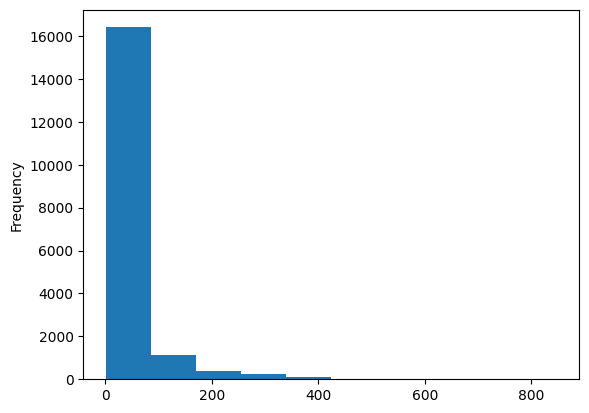

In [50]:
df["question_length"] = df["question"].apply(lambda x: len(x.split()))
df["question_length"].plot(kind='hist')
df.info()

In [51]:
# #exclude one word questions and also very long questions > 500 words
# df = df[(df["question_length"]>2) & (df["question_length"]< 500)]
# df["question_length"].plot(kind='hist')
# df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18324 entries, 507 to 322
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   instruction      18324 non-null  object
 1   question         18324 non-null  object
 2   answer           18324 non-null  object
 3   source           18324 non-null  object
 4   context          18324 non-null  object
 5   complex_cot      1300 non-null   object
 6   category         18324 non-null  object
 7   token_question   18324 non-null  object
 8   token_answer     18324 non-null  object
 9   kind             4225 non-null   object
 10  options          13370 non-null  object
 11  long_answer      11319 non-null  object
 12  extract          1821 non-null   object
 13  type             18324 non-null  object
 14  Product Name     633 non-null    object
 15  Status           20 non-null     object
 16  question_length  18324 non-null  int64 
 17  answer_length    18324 non-null  int

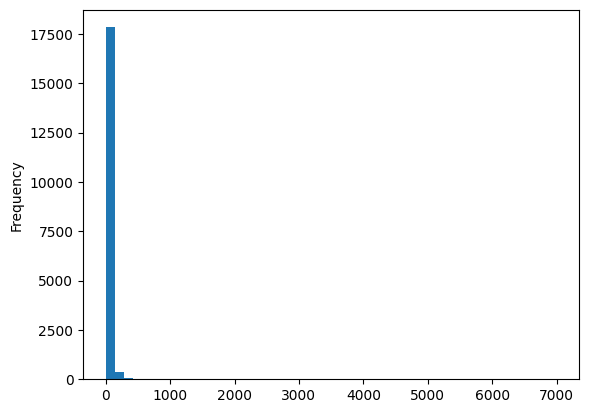

In [57]:
df['answer_length'] = df["answer"].apply(lambda x: len(x.split()))
df['answer_length'].plot(kind='hist', bins=50)
df.info()

<Axes: ylabel='answer_length'>

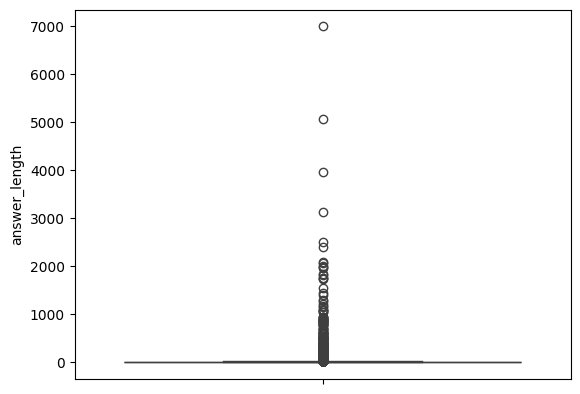

In [66]:
import seaborn as sns
sns.boxplot(df['answer_length'])

<class 'pandas.core.frame.DataFrame'>
Index: 18246 entries, 507 to 322
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   instruction      18246 non-null  object
 1   question         18246 non-null  object
 2   answer           18246 non-null  object
 3   source           18246 non-null  object
 4   context          18246 non-null  object
 5   complex_cot      1300 non-null   object
 6   category         18246 non-null  object
 7   token_question   18246 non-null  object
 8   token_answer     18246 non-null  object
 9   kind             4225 non-null   object
 10  options          13370 non-null  object
 11  long_answer      11319 non-null  object
 12  extract          1821 non-null   object
 13  type             18246 non-null  object
 14  Product Name     633 non-null    object
 15  Status           20 non-null     object
 16  question_length  18246 non-null  int64 
 17  answer_length    18246 non-null  int

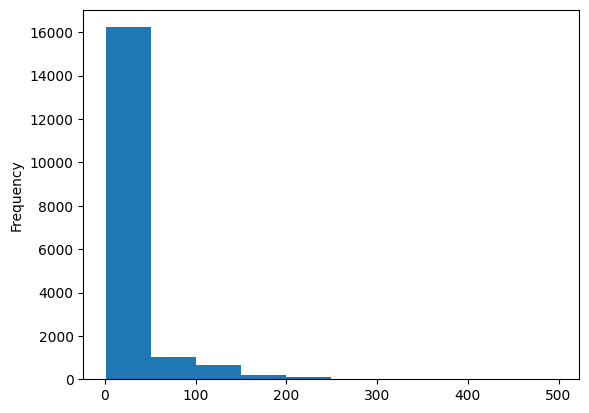

In [67]:
#Remove 500 or more words is the answers
df = df[df["answer_length"]<500]
df['answer_length'].plot(kind='hist')
df.info()

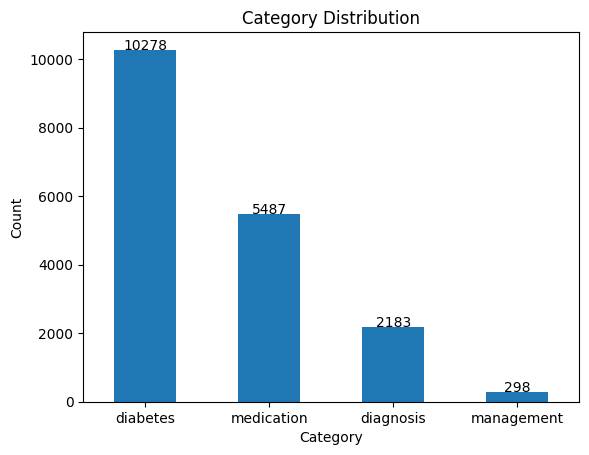

In [68]:
import matplotlib.pyplot as plt
# Plot with Pandas' built-in plot (no 'annot' parameter)
df['category'].value_counts().plot(kind='bar')
plt.title('Category Distribution')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=0)
# Show the values on top of bars
for i, value in enumerate(df['category'].value_counts()):
    plt.text(i, value + 0.5, str(value), ha='center')

plt.show()


In [69]:
df =df.reset_index(drop=True)
# df.to_json("/content/drive/MyDrive/MIT807/data/silver/question_answers/original_df.json")

# Analyse All Data

In [70]:
import nltk
from nltk.probability import FreqDist
nltk.download('words')
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')
nltk.download("punkt_tab")

[nltk_data] Downloading package words to /root/nltk_data...
[nltk_data]   Package words is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## Deduplicate

In [71]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
import pandas as pd
import numpy as np

# PARAMETERS - tune these
N_NEIGHBORS = 10   # how many similar items to retrieve per question (including self)
SIMILARITY_CUTOFF = 0.90
MAX_FEATURES = 50000  # reduce dimensionality if you have many tokens

# prepare documents (apply your remove_stopwords already)
documents = df['question'].astype(str).apply(clean_text).tolist()

vectorizer = TfidfVectorizer(max_features=MAX_FEATURES)
tfidf = vectorizer.fit_transform(documents)  # sparse: shape (N, D)

# Fit NearestNeighbors using cosine (brute force with sparse matrices)
nn = NearestNeighbors(n_neighbors=N_NEIGHBORS, metric='cosine', algorithm='brute', n_jobs=-1)
nn.fit(tfidf)

distances, indices = nn.kneighbors(tfidf, return_distance=True)  # distances in [0, 2] for cosine

# after you compute `distances, indices = nn.kneighbors(tfidf, return_distance=True)`

pairs_map = {}  # key: frozenset({i, j}) -> value: dict with fields below

for i, (dists, inds) in enumerate(zip(distances, indices)):
    for dist, j in zip(dists, inds):
        if i == j:
            continue  # skip self
        sim = 1.0 - dist  # cosine similarity from cosine distance
        if sim < SIMILARITY_CUTOFF:
            continue

        key = frozenset({i, j})
        # normalized ordering for readability: smaller idx first
        i1, i2 = (i, j) if i < j else (j, i)

        # keep the pair with the highest similarity seen (in case both directions appear)
        existing = pairs_map.get(key)
        if existing is None or sim > existing['similarity']:
            pairs_map[key] = {
                'question_1_idx': i1,
                'question_2_idx': i2,
                'question_1': df['question'].iat[i1],
                'question_2': df['question'].iat[i2],
                'similarity': sim
            }

# convert to DataFrame
pairs = pd.DataFrame(list(pairs_map.values()))
pairs = pairs.sort_values('similarity', ascending=False).reset_index(drop=True)

pairs.info()
pairs.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1002 entries, 0 to 1001
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   question_1_idx  1002 non-null   int64  
 1   question_2_idx  1002 non-null   int64  
 2   question_1      1002 non-null   object 
 3   question_2      1002 non-null   object 
 4   similarity      1002 non-null   float64
dtypes: float64(1), int64(2), object(2)
memory usage: 39.3+ KB


,question_1_idx,question_2_idx,question_1,question_2,similarity
0,15674,15675,Which is the most common complication during v...,Which is the most common complication during v...,1.0
1,17551,17574,A 60-year-old man with diabetes mellitus prese...,A 60-year old man with diabetes mellitus prese...,1.0
2,16665,16666,Diabetic gangrene is due to:,Diabetic gangrene is due to A/E,1.0
3,15766,15769,Type I diabetes mellitus is associated with,Type 1 diabetes mellitus is associated with-,1.0
4,14346,16976,True about diabetes in pregnancy are all except:,All are true about diabetes in pregnancy except,1.0


In [72]:
#exclude equal answers - similar answers
pairs_df = pairs.join(df.set_index('question'), on='question_1').join(df.set_index('question'), on='question_2', lsuffix='_1', rsuffix='_2')
eqaul_answers = pairs_df[pairs_df['token_answer_1'].str.lower() == pairs_df['token_answer_2'].str.lower()]
pairs = pairs[~(pairs['question_1'].isin(eqaul_answers['question_1'].tolist()))]
print(len(eqaul_answers))
final_df = df[~df['question'].isin(eqaul_answers['question_1'].tolist())]
final_df.info()

194
<class 'pandas.core.frame.DataFrame'>
Index: 18082 entries, 0 to 18245
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   instruction      18082 non-null  object
 1   question         18082 non-null  object
 2   answer           18082 non-null  object
 3   source           18082 non-null  object
 4   context          18082 non-null  object
 5   complex_cot      1300 non-null   object
 6   category         18082 non-null  object
 7   token_question   18082 non-null  object
 8   token_answer     18082 non-null  object
 9   kind             4064 non-null   object
 10  options          13206 non-null  object
 11  long_answer      11180 non-null  object
 12  extract          1821 non-null   object
 13  type             18082 non-null  object
 14  Product Name     633 non-null    object
 15  Status           20 non-null     object
 16  question_length  18082 non-null  int64 
 17  answer_length    18082 non-null 

In [73]:
#same question and same options
pairs_df = pairs_df[~(pairs_df['question_1'].isin(eqaul_answers['question_1'].tolist()))]
extact_similarities = pairs_df[(pairs_df['options_1'] == pairs_df['options_2'])& (pairs_df['type_1']=='MCQ')]
print(len(extact_similarities))
pairs_df = pairs_df[~(pairs_df['question_1'].isin(extact_similarities['question_2'].tolist()))]
final_df = final_df[~final_df['question'].isin(extact_similarities['question_2'].tolist())]
final_df.info()

3
<class 'pandas.core.frame.DataFrame'>
Index: 18079 entries, 0 to 18245
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   instruction      18079 non-null  object
 1   question         18079 non-null  object
 2   answer           18079 non-null  object
 3   source           18079 non-null  object
 4   context          18079 non-null  object
 5   complex_cot      1300 non-null   object
 6   category         18079 non-null  object
 7   token_question   18079 non-null  object
 8   token_answer     18079 non-null  object
 9   kind             4061 non-null   object
 10  options          13203 non-null  object
 11  long_answer      11177 non-null  object
 12  extract          1821 non-null   object
 13  type             18079 non-null  object
 14  Product Name     633 non-null    object
 15  Status           20 non-null     object
 16  question_length  18079 non-null  int64 
 17  answer_length    18079 non-null  i

In [74]:
def normalize_chat(text):
    # Replace any standalone "chat" (case-insensitive), regardless of spacing/punctuation
    return re.sub(r'\bchat doctor\b', 'Diabetes Virtual Doctor', text, flags=re.IGNORECASE)
final_df['answer'] = final_df['answer'].astype(str).apply(normalize_chat)

,Word,Count,Proportion
19705,lod,1,0.000234
19706,lrguk,1,0.000234
19707,i27l,1,0.000234
19708,7q32,1,0.000234
19709,nhlbi,1,0.000234
19710,emitting,1,0.000234
19711,conduit,1,0.000234
19712,hepatogenous,1,0.000234
19713,variceal,1,0.000234
19714,toets,1,0.000234


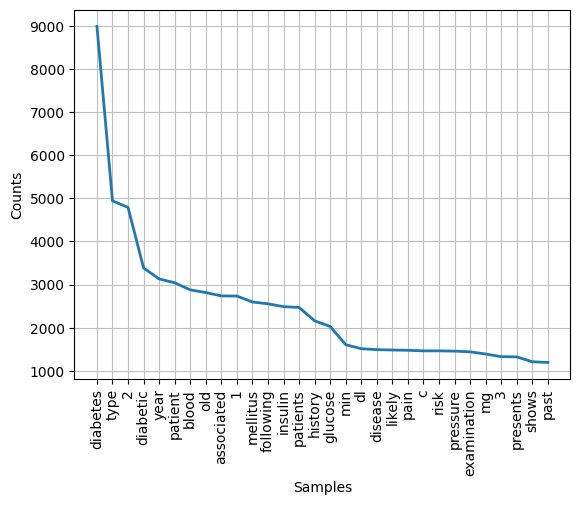

In [75]:
flattened_tokens = list(itertools.chain.from_iterable(final_df['question'].apply(remove_stopwords).str.split().tolist()))
freq_dist = FreqDist(flattened_tokens)
freq_dist.plot(30, cumulative=False)
common_words = pd.DataFrame(freq_dist.items())
common_words.columns = ['Word', 'Count']
common_words['Proportion'] = 100*(common_words['Count']/len(flattened_tokens))
common_words = common_words.sort_values('Proportion', ascending=False).reset_index(drop=True)
common_words.tail(10)

In [76]:
common_words.head(10)

,Word,Count,Proportion
0,diabetes,8983,2.104536
1,type,4940,1.157342
2,2,4788,1.121732
3,diabetic,3384,0.792803
4,year,3131,0.733530
5,patient,3042,0.712679
6,blood,2878,0.674257
7,old,2814,0.659263
8,associated,2738,0.641458
9,1,2734,0.640521


,Word,Count,Proportion
14913,melted,1,0.00046
14914,dipping,1,0.00046
14915,trimesters,1,0.00046
14916,shellfish,1,0.00046
14917,sprouts,1,0.00046
14918,unpasteurised,1,0.00046
14919,tolerable,1,0.00046
14920,crave,1,0.00046
14921,rooibos,1,0.00046
14922,frekwensie,1,0.00046


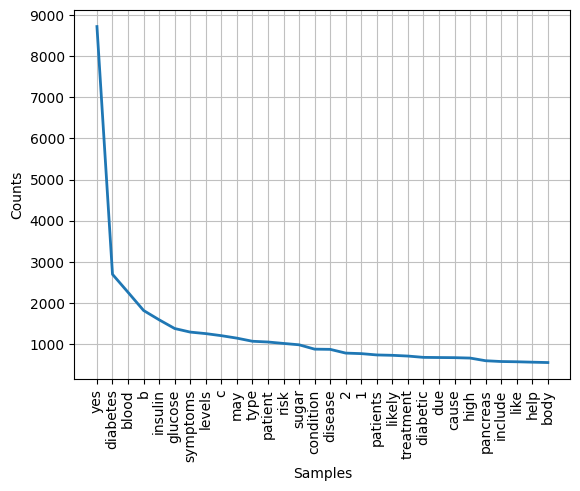

In [77]:
flattened_tokens = list(itertools.chain.from_iterable(final_df['answer'].apply(remove_stopwords).str.split().tolist()))
freq_dist = FreqDist(flattened_tokens)
freq_dist.plot(30, cumulative=False)
common_words = pd.DataFrame(freq_dist.items())
common_words.columns = ['Word', 'Count']
common_words['Proportion'] = 100*(common_words['Count']/len(flattened_tokens))
common_words = common_words.sort_values('Proportion', ascending=False).reset_index(drop=True)
common_words.tail(10)

In [78]:
common_words.head(10)

,Word,Count,Proportion
0,yes,8724,4.012012
1,diabetes,2695,1.239382
2,blood,2257,1.037954
3,b,1815,0.834686
4,insulin,1588,0.730293
5,glucose,1376,0.632798
6,symptoms,1289,0.592788
7,levels,1252,0.575772
8,c,1202,0.552778
9,may,1142,0.525185


## Create WordCloud

In [79]:
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.neighbors import NearestNeighbors
# import pandas as pd
# import numpy as np

# # PARAMETERS - tune these
# N_NEIGHBORS = 10   # how many similar items to retrieve per question (including self)
# SIMILARITY_CUTOFF = 0.90
# MAX_FEATURES = 50000  # reduce dimensionality if you have many tokens

# # prepare documents (apply your remove_stopwords already)
# documents = final_df['question'].astype(str).apply(clean_text).tolist()

# vectorizer = TfidfVectorizer(max_features=MAX_FEATURES)
# tfidf = vectorizer.fit_transform(documents)  # sparse: shape (N, D)

# # Fit NearestNeighbors using cosine (brute force with sparse matrices)
# nn = NearestNeighbors(n_neighbors=N_NEIGHBORS, metric='cosine', algorithm='brute', n_jobs=-1)
# nn.fit(tfidf)

# distances, indices = nn.kneighbors(tfidf, return_distance=True)  # distances in [0, 2] for cosine

# # after you compute `distances, indices = nn.kneighbors(tfidf, return_distance=True)`

# pairs_map = {}  # key: frozenset({i, j}) -> value: dict with fields below

# for i, (dists, inds) in enumerate(zip(distances, indices)):
#     for dist, j in zip(dists, inds):
#         if i == j:
#             continue  # skip self
#         sim = 1.0 - dist  # cosine similarity from cosine distance
#         if sim < SIMILARITY_CUTOFF:
#             continue

#         key = frozenset({i, j})
#         # normalized ordering for readability: smaller idx first
#         i1, i2 = (i, j) if i < j else (j, i)

#         # keep the pair with the highest similarity seen (in case both directions appear)
#         existing = pairs_map.get(key)
#         if existing is None or sim > existing['similarity']:
#             pairs_map[key] = {
#                 'question_1_idx': i1,
#                 'question_2_idx': i2,
#                 'question_1': df['question'].iat[i1],
#                 'question_2': df['question'].iat[i2],
#                 'similarity': sim
#             }

# # convert to DataFrame
# pairs = pd.DataFrame(list(pairs_map.values()))
# pairs = pairs.sort_values('similarity', ascending=False).reset_index(drop=True)

# pairs.info()
# pairs.head()

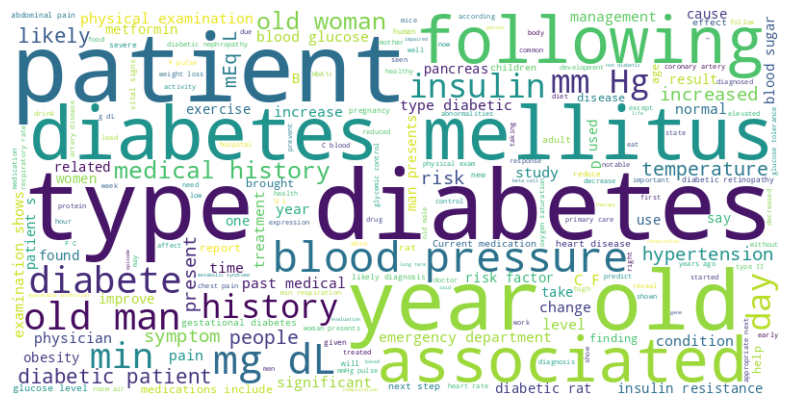

In [80]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Pick the column you want to visualize
text = " ".join(final_df['question'].astype(str))

# Generate word cloud
wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)

# Display it
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

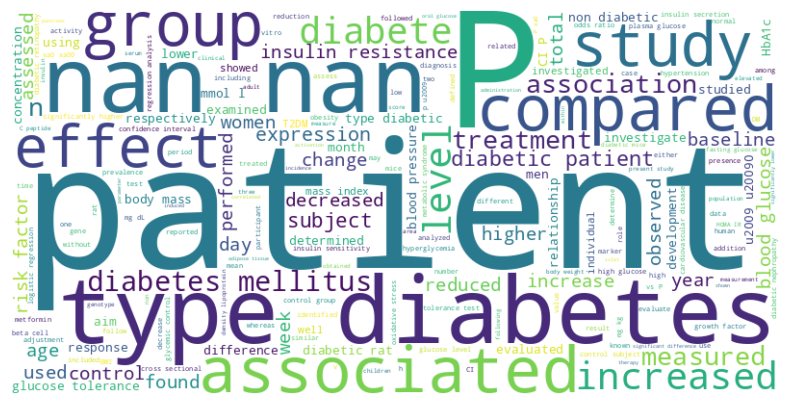

In [81]:
# Pick the column you want to visualize
text = " ".join(final_df['context'].dropna().astype(str))

# Generate word cloud
wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)

# Display it
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

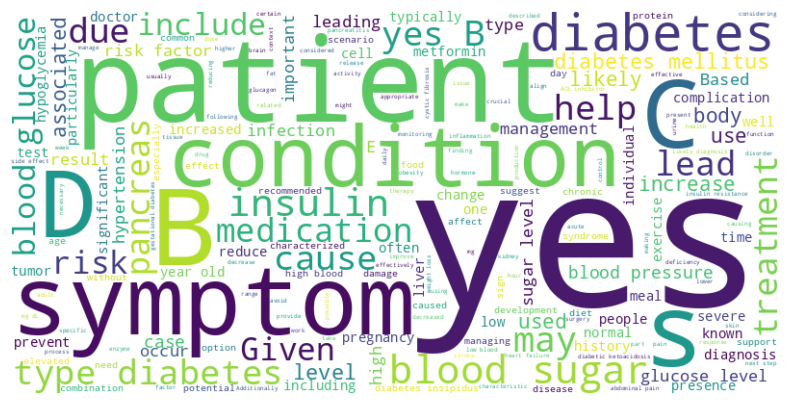

In [82]:
# Pick the column you want to visualize
text = " ".join(final_df['answer'].astype(str))

# Generate word cloud
wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)

# Display it
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

## Split data into test and train

In [83]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18079 entries, 0 to 18245
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   instruction      18079 non-null  object
 1   question         18079 non-null  object
 2   answer           18079 non-null  object
 3   source           18079 non-null  object
 4   context          18079 non-null  object
 5   complex_cot      1300 non-null   object
 6   category         18079 non-null  object
 7   token_question   18079 non-null  object
 8   token_answer     18079 non-null  object
 9   kind             4061 non-null   object
 10  options          13203 non-null  object
 11  long_answer      11177 non-null  object
 12  extract          1821 non-null   object
 13  type             18079 non-null  object
 14  Product Name     633 non-null    object
 15  Status           20 non-null     object
 16  question_length  18079 non-null  int64 
 17  answer_length    18079 non-null  int

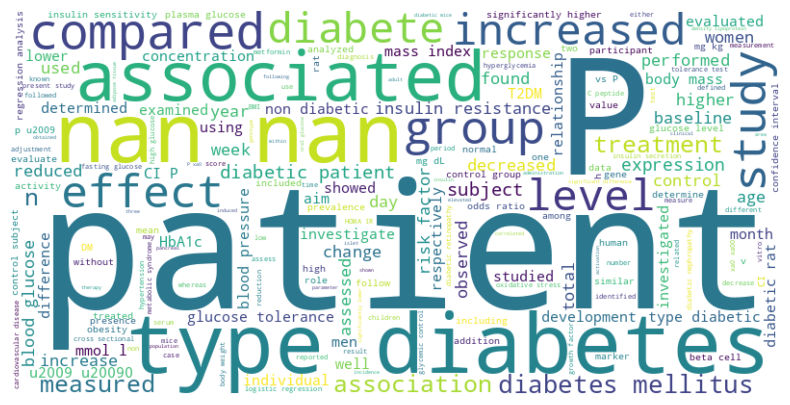

In [84]:
# Pick the column you want to visualize
text = " ".join(final_df['context'].dropna().astype(str))

# Generate word cloud
wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)

# Display it
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

In [85]:
final_df[final_df['type']== 'MCQ'].info()

<class 'pandas.core.frame.DataFrame'>
Index: 13203 entries, 3742 to 18239
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   instruction      13203 non-null  object
 1   question         13203 non-null  object
 2   answer           13203 non-null  object
 3   source           13203 non-null  object
 4   context          13203 non-null  object
 5   complex_cot      0 non-null      object
 6   category         13203 non-null  object
 7   token_question   13203 non-null  object
 8   token_answer     13203 non-null  object
 9   kind             4049 non-null   object
 10  options          13203 non-null  object
 11  long_answer      11177 non-null  object
 12  extract          0 non-null      object
 13  type             13203 non-null  object
 14  Product Name     0 non-null      object
 15  Status           0 non-null      object
 16  question_length  13203 non-null  int64 
 17  answer_length    13203 non-null  

In [86]:
import ast

def get_letter(row):
    if row['type'] != 'MCQ':
        return row['answer']

    opts = row['options']

    # Convert stringified dict to real dict if needed
    if isinstance(opts, str):
        try:
            opts = ast.literal_eval(opts)
        except:
            return row['answer']  # fallback if parsing fails

    ans = row['answer']

    # If answer is a key, return "letter: value"
    if ans in opts:
        return f"{ans}: {opts[ans]}"

    # Otherwise, search for the value and return "letter: value"
    for k, v in opts.items():
        if str(v).strip().lower() == str(ans).strip().lower():
            return f"{k}: {v}"

    # fallback if no match
    return ans

final_df['answer'] = final_df.apply(get_letter, axis=1)

In [87]:
test_df = final_df[final_df['kind'] == 'test']
test_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 185 entries, 13962 to 18134
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   instruction      185 non-null    object
 1   question         185 non-null    object
 2   answer           185 non-null    object
 3   source           185 non-null    object
 4   context          185 non-null    object
 5   complex_cot      0 non-null      object
 6   category         185 non-null    object
 7   token_question   185 non-null    object
 8   token_answer     185 non-null    object
 9   kind             185 non-null    object
 10  options          173 non-null    object
 11  long_answer      0 non-null      object
 12  extract          0 non-null      object
 13  type             185 non-null    object
 14  Product Name     0 non-null      object
 15  Status           0 non-null      object
 16  question_length  185 non-null    int64 
 17  answer_length    185 non-null    i

In [88]:
split_df = final_df[~(final_df['kind'] == 'test')]
split_df = split_df.reset_index(drop=True)
split_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17894 entries, 0 to 17893
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   instruction      17894 non-null  object
 1   question         17894 non-null  object
 2   answer           17894 non-null  object
 3   source           17894 non-null  object
 4   context          17894 non-null  object
 5   complex_cot      1300 non-null   object
 6   category         17894 non-null  object
 7   token_question   17894 non-null  object
 8   token_answer     17894 non-null  object
 9   kind             3876 non-null   object
 10  options          13030 non-null  object
 11  long_answer      11177 non-null  object
 12  extract          1821 non-null   object
 13  type             17894 non-null  object
 14  Product Name     633 non-null    object
 15  Status           20 non-null     object
 16  question_length  17894 non-null  int64 
 17  answer_length    17894 non-null

In [89]:
from sklearn.model_selection import train_test_split

# Split the entire df (keeps it as DataFrames)
df_train, df_test = train_test_split(
    split_df,
    test_size=0.10,          # or an int like 4 to use exactly 4 rows for test
    random_state=42,
    stratify=split_df['type'].astype(str) + '_' + split_df['category'].astype(str)   # optional for classification to keep class balance
)

# (Optional) reset indices if you prefer contiguous indexes
df_train = pd.concat([df_train]).reset_index(drop=True)
df_test  = pd.concat([df_test, test_df]).reset_index(drop=True)

In [90]:
final_custom_df['source'].unique()

array(['professional information', 'patient information leaflet',
       'Consumer queries', 'literature', 'guidelines',
       'SAHPRA guidelines', 'Diet/Exercise Diabetes Management', 'facts',
       'FAQ and Other QAs'], dtype=object)

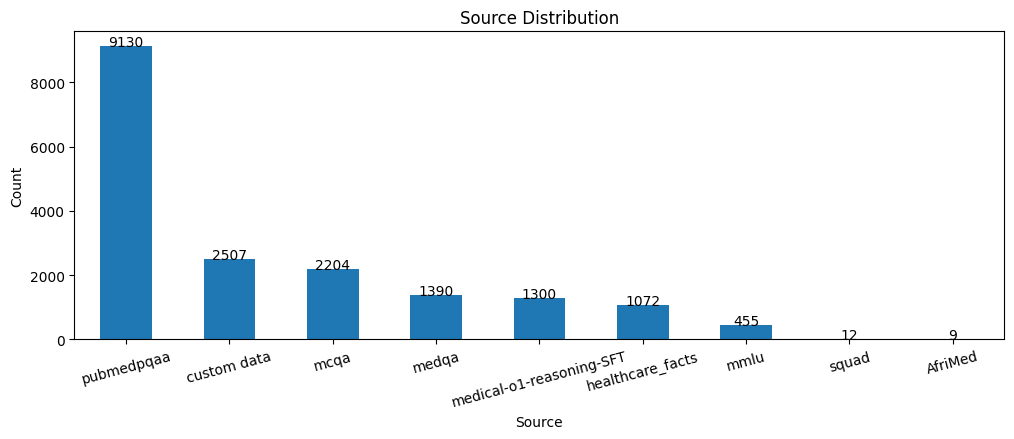

In [97]:
import matplotlib.pyplot as plt
graph_df = final_df['source'].replace({
    'professional information': 'custom data',
    'patient information leaflet': 'custom data',
    'Consumer queries': 'custom data',
    'literature': 'custom data',
    'guidelines': 'custom data',
    'SAHPRA guidelines': 'custom data',
    'Diet/Exercise Diabetes Management': 'custom data',
    'facts': 'custom data',
    'FAQ and Other QAs': 'custom data'
})

graph_df.value_counts().plot(kind='bar', figsize=(12,4))
plt.title('Source Distribution')
plt.xlabel('Source')
plt.ylabel('Count')
# Show the values on top of bars
for i, value in enumerate(graph_df.value_counts()):
    plt.text(i, value + 0.5, str(value), ha='center')
plt.xticks(rotation=15)
plt.show()

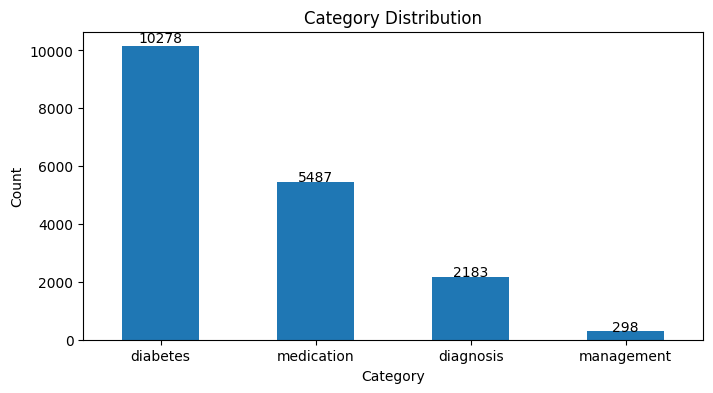

In [99]:
import matplotlib.pyplot as plt
final_df['category'].value_counts().plot(kind='bar', figsize=(8,4))
plt.title('Category Distribution')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=0)
# Show the values on top of bars
for i, value in enumerate(df['category'].value_counts()):
    plt.text(i, value + 0.4, str(value), ha='center')
plt.show()

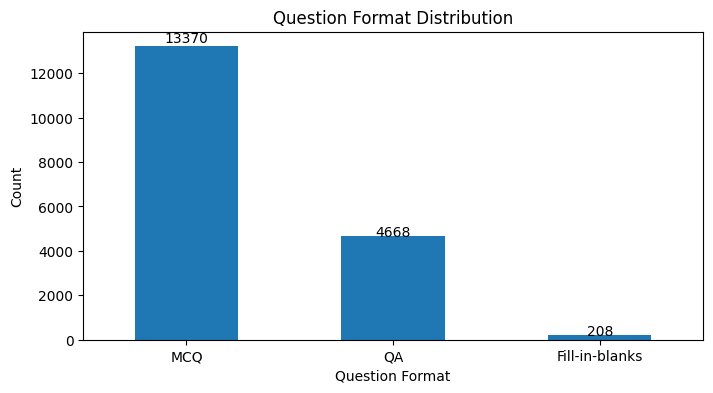

In [100]:
import matplotlib.pyplot as plt
final_df['type'].value_counts().plot(kind='bar', figsize=(8,4))
plt.title('Question Format Distribution')
plt.xlabel('Question Format')
plt.ylabel('Count')
plt.xticks(rotation=0)
# Show the values on top of bars
for i, value in enumerate(df['type'].value_counts()):
    plt.text(i, value + 0.4, str(value), ha='center')
plt.show()

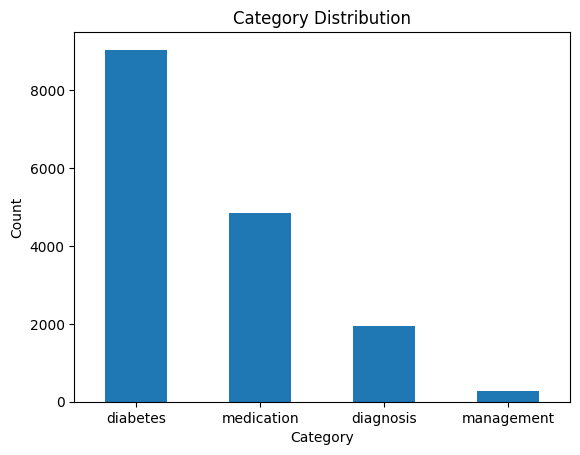

In [ ]:
import matplotlib.pyplot as plt
df_train['category'].value_counts().plot(kind='bar')
plt.title('Category Distribution')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

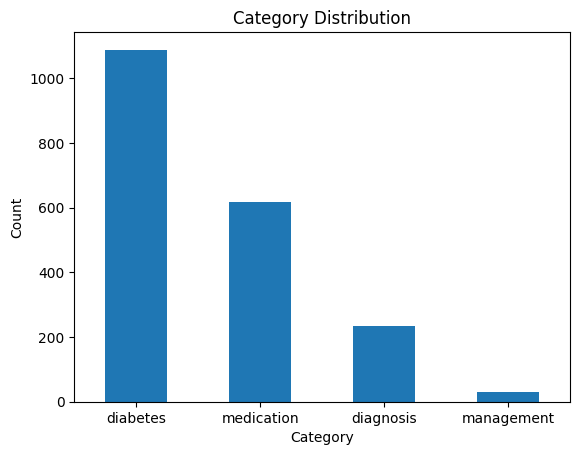

In [ ]:
import matplotlib.pyplot as plt
df_test['category'].value_counts().plot(kind='bar')
plt.title('Category Distribution')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

In [ ]:
# df_test.to_json("/content/drive/MyDrive/MIT807/data/silver/question_answers/test.json")
# df_train.to_json("/content/drive/MyDrive/MIT807/data/silver/question_answers/training.json")

## Add topics to the dataset